# 02 - Pipeline Runtime Benchmark

Mierzy czas potrzebny do przygotowania danych (Rust pipeline) i treningu ML dla każdego organizmu.
Dane pobierane są automatycznie z `benchmark_results.json` (zapisywanego przez `prepare_genomes.sh`) oraz z logów `run_experiments.log`.

In [6]:
import json
import re
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

_here = Path().resolve()
REPO_ROOT = next(p for p in [_here, *_here.parents] if (p / 'Cargo.toml').exists())

RESULTS_DIR = REPO_ROOT / 'experiments' / 'transfer' / 'results'
CONFIG_PATH = REPO_ROOT / 'experiments' / 'transfer' / 'config' / 'organisms.yaml'

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f)
organisms = config['organisms']

print('REPO_ROOT:', REPO_ROOT)
print('Organisms:', list(organisms.keys()))

REPO_ROOT: /home/ziutek/fstudies/inz/dna-assembler-ml
Organisms: ['ecoli', 'cerevisiae', 'bsubtilis', 'mtuberculosis', 'hpylori']


In [7]:
benchmark_path = RESULTS_DIR / 'benchmark' / 'benchmark_results.json'

if benchmark_path.exists():
    with open(benchmark_path) as f:
        bench_data = json.load(f)
    df = pd.DataFrame(bench_data)
    print(f'Loaded {len(df)} organisms from benchmark.')
else:
    print(f'WARNING: {benchmark_path} not found.')
    print('Run: bash experiments/transfer/prepare_genomes.sh')
    df = pd.DataFrame(columns=['organism', 'genome_size_mbp', 'pipeline_time_s', 'total_junctions'])

df = df.sort_values('genome_size_mbp').reset_index(drop=True)
df

Loaded 5 organisms from benchmark.


,organism,genome_size_mbp,pipeline_time_s,total_junctions
0,hpylori,1.66,26.512,207
1,bsubtilis,4.21,80.391,232
2,mtuberculosis,4.41,103.093,701
3,ecoli,4.64,129.056,703
4,cerevisiae,12.15,658.403,3742


## Pipeline time vs genome size

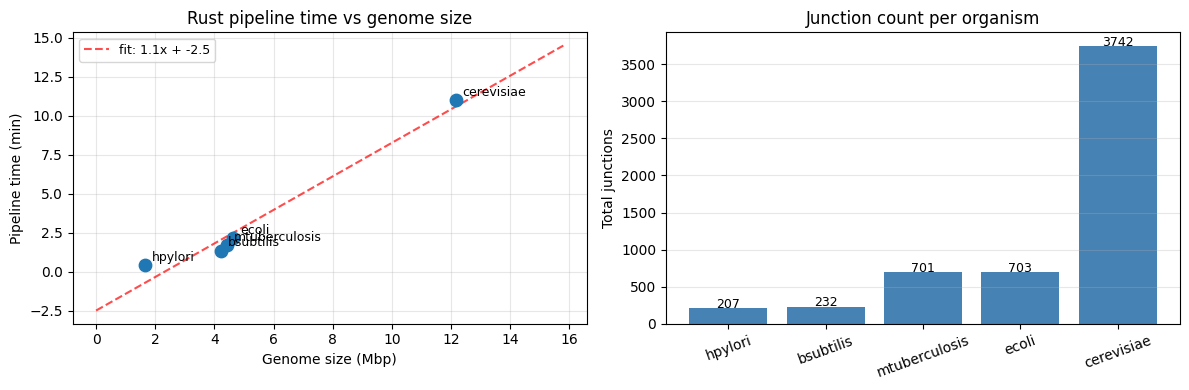

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
valid = df.dropna(subset=['pipeline_time_s', 'genome_size_mbp'])
ax.scatter(valid['genome_size_mbp'], valid['pipeline_time_s'] / 60, s=80, zorder=3)

for _, row in valid.iterrows():
    ax.annotate(row['organism'], (row['genome_size_mbp'], row['pipeline_time_s'] / 60),
                textcoords='offset points', xytext=(5, 3), fontsize=9)

if len(valid) >= 2:
    x = valid['genome_size_mbp'].values
    y = valid['pipeline_time_s'].values / 60
    coeffs = np.polyfit(x, y, 1)
    x_line = np.linspace(0, x.max() * 1.3, 100)
    ax.plot(x_line, np.polyval(coeffs, x_line), 'r--', alpha=0.7,
            label=f'fit: {coeffs[0]:.1f}x + {coeffs[1]:.1f}')
    ax.legend(fontsize=9)

ax.set_xlabel('Genome size (Mbp)')
ax.set_ylabel('Pipeline time (min)')
ax.set_title('Rust pipeline time vs genome size')
ax.grid(True, alpha=0.3)

ax2 = axes[1]
valid2 = df.dropna(subset=['total_junctions'])
bars = ax2.bar(valid2['organism'], valid2['total_junctions'], color='steelblue')
ax2.set_ylabel('Total junctions')
ax2.set_title('Junction count per organism')
ax2.tick_params(axis='x', rotation=20)
ax2.grid(True, axis='y', alpha=0.3)

for bar, val in zip(bars, valid2['total_junctions']):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             str(int(val)), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## Czas treningu ML (z logów)

In [9]:
LOG_FILE = RESULTS_DIR / 'run_experiments.log'

avg_training_min = None

if LOG_FILE.exists():
    text = LOG_FILE.read_text(encoding='utf-8')

    start_pat = re.compile(
        r'(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) \[INFO\] \$ .*main\.py train'
    )
    done_pat = re.compile(
        r'(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) \[INFO\] Solo training done: (\w+)'
    )

    starts = [(datetime.strptime(m.group(1), '%Y-%m-%d %H:%M:%S'), m.start())
              for m in start_pat.finditer(text)]
    dones  = [(datetime.strptime(m.group(1), '%Y-%m-%d %H:%M:%S'), m.group(2), m.start())
              for m in done_pat.finditer(text)]

    durations = []
    for done_time, name, done_pos in dones:
        prior = [(t, p) for t, p in starts if p < done_pos]
        if prior:
            dur_min = (done_time - prior[-1][0]).total_seconds() / 60
            durations.append((name, dur_min))
            print(f'  {name}: {dur_min:.1f} min')

    if durations:
        avg_training_min = sum(d for _, d in durations) / len(durations)
        print(f'\nŚredni czas treningu solo: {avg_training_min:.1f} min')
    else:
        print('Nie znaleziono wpisów o treningu w logu.')
else:
    print(f'Plik logu nie istnieje: {LOG_FILE}')
    print('Uruchom najpierw: python experiments/transfer/run_experiments.py')

  ecoli: 0.3 min
  cerevisiae: 1.0 min
  bsubtilis: 0.1 min
  mtuberculosis: 0.4 min
  hpylori: 0.2 min
  ecoli: 0.3 min
  cerevisiae: 1.0 min
  bsubtilis: 0.1 min
  mtuberculosis: 0.5 min
  hpylori: 0.1 min

Średni czas treningu solo: 0.4 min


## Szacowany czas eksperymentu dla N organizmów

Tabela pokazuje **szacowany** czas (nie zmierzony), gdyby eksperyment był powtórzony dla większej liczby organizmów.
Wartości obliczane na podstawie średnich zmierzonych powyżej.

In [10]:
if avg_training_min is not None and len(df) > 0:
    avg_pipeline_min = df['pipeline_time_s'].mean() / 60

    N_values = [3, 5, 7, 10]
    rows = []
    for N in N_values:
        n_solo     = N
        n_finetune = N * (N - 1)
        solo_total = n_solo     * avg_training_min
        ft_total   = n_finetune * avg_training_min
        pipe_total = N          * avg_pipeline_min
        total_min  = solo_total + ft_total + pipe_total
        rows.append({
            'N': N,
            'przebiegi solo': n_solo,
            'przebiegi fine-tune': n_finetune,
            'pipeline (min)': round(pipe_total, 1),
            'solo trening (min)': round(solo_total, 1),
            'fine-tune trening (min)': round(ft_total, 1),
            'łącznie (min)': round(total_min, 1),
            'łącznie (h)': round(total_min / 60, 2),
        })

    extrap_df = pd.DataFrame(rows).set_index('N')
    print(f'Avg czas pipeline: {avg_pipeline_min:.1f} min/organizm')
    print(f'Avg czas treningu: {avg_training_min:.1f} min/przebieg\n')
    display(extrap_df)
else:
    print('Brak danych - uruchom pipeline i trening najpierw.')

Avg czas pipeline: 3.3 min/organizm
Avg czas treningu: 0.4 min/przebieg



,przebiegi solo,przebiegi fine-tune,pipeline (min),solo trening (min),fine-tune trening (min),łącznie (min),łącznie (h)
N,,,,,,,
3,3,6,10.0,1.2,2.4,13.6,0.23
5,5,20,16.6,2.0,8.1,26.8,0.45
7,7,42,23.3,2.8,17.1,43.2,0.72
10,10,90,33.2,4.1,36.6,73.9,1.23
